# Optimizing LoRA Fine-Tuning for Skin Lesion Classification

This notebook compares frozen-backbone linear probing with rank-4 LoRA on pretrained DeiT-Tiny using the predefined DermaMNIST training, validation, and test splits. Both experiments share the same seed, three epochs, learning rate, batch size, image preprocessing, optimizer, and loss. Each section explains its purpose before the associated code.

Training is **opt-in**. Setup, data inspection, model checks, and evaluation helpers do not launch training. Set `RUN_TRAINING = True` in the training cell only when you are ready to run both experiments; actual metrics and history will then be saved under `results/`. No results are prefilled.

## 1. Environment

This setup cell installs the Python libraries used by the experiment. It does not download the dataset, load model weights, or start training. Install a PyTorch build compatible with your machine separately if PyTorch is not already available.

In [1]:
%pip install medmnist transformers peft scikit-learn pandas matplotlib

   ---------------------------------------- 0.0/835.4 kB ? eta -:--:--
   --------------------------------------- 835.4/835.4 kB 12.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   -------------------------------------- - 14.9/15.5 MB 72.3 MB/s eta 0:00:01
   ---------------------------------------- 15.5/15.5 MB 61.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 36.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   --- ------------------------------------ 11.0/126.7 MB 57.5 MB/s eta 0:00:03
   ------- -------------------------------- 23.6/126.7 MB 57.5 MB/s eta 0:00:02
   ------------ --------------------------- 41.2/126.7 MB 67.2 MB/s eta 0:00:02
   ----------------- ---------------------- 56.1/126.7 MB 68.8 MB/s eta 0:00:02
   --------------------- ------------------ 66.8/126.7 MB 63.6 MB/s eta 0:00:01
   -

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.7.1 which is incompatible.
pycaret 3.3.2 requires matplotlib<3.8.0, but you have matplotlib 3.10.3 which is incompatible.
pycaret 3.3.2 requires pandas<2.2.0, but you have pandas 2.3.3 which is incompatible.
sktime 0.26.0 requires pandas<2.2.0,>=1.1, but you have pandas 2.3.3 which is incompatible.
sktime 0.26.0 requires scikit-learn<1.5.0,>=0.24, but you have scikit-learn 1.7.1 which is incompatible.
autoviz 0.1.905 requires xgboost<1.7,>=0.82, but you have xgboost 3.0.2 which is incompatible.
open

## 2. Shared configuration

This cell imports the shared libraries and fixes the experimental settings. Both methods use the same seed, three epochs, learning rate, batch size, image processor, data splits, and AdamW settings. Change these values only if you intend to rerun both methods with the same updated configuration.

In [3]:
import json
import random
from pathlib import Path

import medmnist
import numpy as np
import pandas as pd
import torch
from medmnist import DermaMNIST
from sklearn.metrics import balanced_accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader
from transformers import AutoImageProcessor, DeiTForImageClassification

SEED = 594
EPOCHS = 3
BATCH_SIZE = 32
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
NUM_CLASSES = 7
MODEL_NAME = "facebook/deit-tiny-patch16-224"
RESULTS_DIR = Path("results")


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | MedMNIST: {medmnist.__version__}")
print(f"Device: {DEVICE} | seed={SEED} | epochs={EPOCHS} | batch_size={BATCH_SIZE}")

PyTorch: 2.15.0+cpu | MedMNIST: 3.0.2
Device: cpu | seed=594 | epochs=3 | batch_size=32


## 3. Predefined DermaMNIST+ splits

This cell uses MedMNIST's official train, validation, and test splits at size 224 with RGB conversion. The Hugging Face image processor applies the checkpoint's expected resize and normalization. Running this cell may download the dataset and processor files; it does not train a model.

In [4]:
image_processor = AutoImageProcessor.from_pretrained(MODEL_NAME)


class DeiTImageTransform:
    def __call__(self, image):
        return image_processor(images=image, return_tensors="pt")["pixel_values"].squeeze(0)


image_transform = DeiTImageTransform()
datasets = {
    split: DermaMNIST(
        split=split,
        size=224,
        as_rgb=True,
        transform=image_transform,
        download=True,
    )
    for split in ("train", "val", "test")
}

for split, dataset in datasets.items():
    print(f"{split:>5}: {len(dataset):,} images")
print("Image processor:", image_processor.__class__.__name__)
print("Class names:", getattr(datasets["train"], "info", {}).get("label", "see MedMNIST metadata"))

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
100%|██████████| 1.09G/1.09G [04:40<00:00, 3.89MB/s] 


train: 7,007 images
  val: 1,003 images
 test: 2,005 images
Image processor: ViTImageProcessor
Class names: {'0': 'actinic keratoses and intraepithelial carcinoma', '1': 'basal cell carcinoma', '2': 'benign keratosis-like lesions', '3': 'dermatofibroma', '4': 'melanoma', '5': 'melanocytic nevi', '6': 'vascular lesions'}


## 4. Model and trainable-parameter checks

This cell first lists the query/value projection names in pretrained DeiT-Tiny, then checks the trainable parameters in each configuration. The linear-probing model must train only its classifier. The LoRA model must train rank-4 adapters on query/value and PEFT's saved classifier copy, with all original backbone weights frozen. Any mismatch raises an assertion before training.

In [9]:

import torch
import random
import numpy as np

from peft import LoraConfig, get_peft_model
from transformers import ViTForImageClassification

# ------------------------------------------
# 1. Configuration
# ------------------------------------------

MODEL_NAME = "facebook/deit-tiny-patch16-224"
NUM_CLASSES = 7
SEED = 42

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ------------------------------------------
# 2. Load pretrained DeiT-Tiny
# ------------------------------------------

def load_base_model():
    seed_everything(SEED)

    model = ViTForImageClassification.from_pretrained(
        MODEL_NAME,
        num_labels=NUM_CLASSES,
        ignore_mismatched_sizes=True
    )

    return model


base_model = load_base_model()

print("Pretrained DeiT-Tiny loaded successfully!")


# ------------------------------------------
# 3. Identify attention projections
# ------------------------------------------

attention_projection_names = [
    name
    for name, _ in base_model.named_modules()
    if name.endswith((".query", ".value"))
]

query_names = [
    name
    for name in attention_projection_names
    if name.endswith(".query")
]

value_names = [
    name
    for name in attention_projection_names
    if name.endswith(".value")
]

print("Query projection examples:", query_names[:2])
print("Value projection examples:", value_names[:2])

assert len(query_names) == 12 and len(value_names) == 12, (
    f"Expected 12 query and value modules; "
    f"found {len(query_names)} and {len(value_names)}"
)


# ------------------------------------------
# 4. Linear probing baseline
# ------------------------------------------

# Freeze all pretrained parameters
for parameter in base_model.parameters():
    parameter.requires_grad = False

# Unfreeze only classification head
for parameter in base_model.classifier.parameters():
    parameter.requires_grad = True

linear_trainable = [
    name
    for name, parameter in base_model.named_parameters()
    if parameter.requires_grad
]

assert linear_trainable and all(
    name.startswith("classifier.")
    for name in linear_trainable
)

linear_param_count = sum(
    parameter.numel()
    for parameter in base_model.parameters()
    if parameter.requires_grad
)

print("\nLinear probing baseline")
print("Trainable parameter names:", linear_trainable)
print("Trainable parameter count:", linear_param_count)


# ------------------------------------------
# 5. LoRA rank 4 configuration
# ------------------------------------------

lora_config = LoraConfig(
    r=4,
    lora_alpha=8,
    lora_dropout=0.1,
    target_modules=["query", "value"],
    modules_to_save=["classifier"],
    bias="none",
)

# Fresh pretrained model for LoRA
lora_model = get_peft_model(
    load_base_model(),
    lora_config
)

lora_trainable = [
    name
    for name, parameter in lora_model.named_parameters()
    if parameter.requires_grad
]

assert any(
    "lora_A" in name
    for name in lora_trainable
)

assert any(
    "lora_B" in name
    for name in lora_trainable
)

assert any(
    "classifier" in name and "modules_to_save" in name
    for name in lora_trainable
)

assert all(
    "lora_" in name or "modules_to_save" in name
    for name in lora_trainable
), "Unexpected trainable base-model parameter found"

lora_param_count = sum(
    parameter.numel()
    for parameter in lora_model.parameters()
    if parameter.requires_grad
)

print("\nLoRA Rank 4")
print("Trainable parameter tensors:", len(lora_trainable))
print("Trainable parameter count:", lora_param_count)
print("First 12 trainable parameters:", lora_trainable[:12])


# ------------------------------------------
# 6. Compare trainable parameters
# ------------------------------------------

print("\nPARAMETER COMPARISON")
print("-" * 45)

print(f"Linear probing: {linear_param_count:,}")
print(f"LoRA rank 4:    {lora_param_count:,}")

print("-" * 45)


# ------------------------------------------
# 7. Memory cleanup
# ------------------------------------------

del base_model
del lora_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nModel configuration checks completed!")



Some weights of ViTForImageClassification were not initialized from the model checkpoint at facebook/deit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([7, 192]) in the model instantiated
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([7]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Pretrained DeiT-Tiny loaded successfully!
Query projection examples: ['vit.encoder.layer.0.attention.attention.query', 'vit.encoder.layer.1.attention.attention.query']
Value projection examples: ['vit.encoder.layer.0.attention.attention.value', 'vit.encoder.layer.1.attention.attention.value']

Linear probing baseline
Trainable parameter names: ['classifier.weight', 'classifier.bias']
Trainable parameter count: 1351


Some weights of ViTForImageClassification were not initialized from the model checkpoint at facebook/deit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([7, 192]) in the model instantiated
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([7]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



LoRA Rank 4
Trainable parameter tensors: 50
Trainable parameter count: 38215
First 12 trainable parameters: ['base_model.model.vit.encoder.layer.0.attention.attention.query.lora_A.default.weight', 'base_model.model.vit.encoder.layer.0.attention.attention.query.lora_B.default.weight', 'base_model.model.vit.encoder.layer.0.attention.attention.value.lora_A.default.weight', 'base_model.model.vit.encoder.layer.0.attention.attention.value.lora_B.default.weight', 'base_model.model.vit.encoder.layer.1.attention.attention.query.lora_A.default.weight', 'base_model.model.vit.encoder.layer.1.attention.attention.query.lora_B.default.weight', 'base_model.model.vit.encoder.layer.1.attention.attention.value.lora_A.default.weight', 'base_model.model.vit.encoder.layer.1.attention.attention.value.lora_B.default.weight', 'base_model.model.vit.encoder.layer.2.attention.attention.query.lora_A.default.weight', 'base_model.model.vit.encoder.layer.2.attention.attention.query.lora_B.default.weight', 'base_mode

In [6]:
print(MODEL_NAME)

facebook/deit-tiny-patch16-224


## 5. Training and evaluation functions

This cell defines one shared training loop for both approaches. It records sample-weighted training and validation cross-entropy each epoch, keeps the checkpoint with the lowest validation loss, and reports balanced accuracy and macro-F1 on the untouched test split. No loop runs until the opt-in cell below is enabled.

In [10]:
def make_model(experiment):
    model = load_base_model()
    if experiment == "linear_probe":
        for parameter in model.parameters():
            parameter.requires_grad = False
        for parameter in model.classifier.parameters():
            parameter.requires_grad = True
    elif experiment == "lora_rank4":
        model = get_peft_model(model, lora_config)
    else:
        raise ValueError(f"Unknown experiment: {experiment}")
    return model


def make_loaders():
    train_generator = torch.Generator().manual_seed(SEED)
    return {
        "train": DataLoader(
            datasets["train"], batch_size=BATCH_SIZE, shuffle=True, generator=train_generator
        ),
        "val": DataLoader(datasets["val"], batch_size=BATCH_SIZE, shuffle=False),
        "test": DataLoader(datasets["test"], batch_size=BATCH_SIZE, shuffle=False),
    }


def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0.0
    total_examples = 0
    for pixel_values, labels in loader:
        pixel_values = pixel_values.to(DEVICE)
        labels = labels.reshape(-1).long().to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(pixel_values=pixel_values).logits
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_examples += labels.size(0)
    return total_loss / total_examples


@torch.no_grad()
def evaluate_loss(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    total_examples = 0
    for pixel_values, labels in loader:
        pixel_values = pixel_values.to(DEVICE)
        labels = labels.reshape(-1).long().to(DEVICE)
        logits = model(pixel_values=pixel_values).logits
        total_loss += loss_fn(logits, labels).item() * labels.size(0)
        total_examples += labels.size(0)
    return total_loss / total_examples


@torch.no_grad()
def evaluate_test(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    total_examples = 0
    all_labels, all_predictions = [], []
    for pixel_values, labels in loader:
        pixel_values = pixel_values.to(DEVICE)
        labels = labels.reshape(-1).long().to(DEVICE)
        logits = model(pixel_values=pixel_values).logits
        total_loss += loss_fn(logits, labels).item() * labels.size(0)
        total_examples += labels.size(0)
        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(logits.argmax(dim=-1).cpu().tolist())
    return {
        "test_loss": total_loss / total_examples,
        "test_balanced_accuracy": balanced_accuracy_score(all_labels, all_predictions),
        "test_macro_f1": f1_score(all_labels, all_predictions, average="macro", zero_division=0),
    }


def run_experiment(experiment):
    seed_everything(SEED)
    loaders = make_loaders()
    model = make_model(experiment).to(DEVICE)
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    if not trainable:
        raise RuntimeError(f"No trainable parameters for {experiment}")
    optimizer = torch.optim.AdamW(
        trainable, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    loss_fn = nn.CrossEntropyLoss()
    history = []
    best_val_loss = float("inf")
    best_train_loss = None
    best_epoch = None
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        train_loss = train_one_epoch(model, loaders["train"], optimizer, loss_fn)
        val_loss = evaluate_loss(model, loaders["val"], loss_fn)
        history.append({"experiment": experiment, "epoch": epoch, "train_loss": train_loss, "validation_loss": val_loss})
        print(f"{experiment} | epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f} | validation loss {val_loss:.4f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_train_loss = train_loss
            best_epoch = epoch
            best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}

    model.load_state_dict(best_state)
    test_metrics = evaluate_test(model, loaders["test"], loss_fn)
    summary = {
        "experiment": experiment,
        "best_epoch": best_epoch,
        "train_loss_at_best_epoch": best_train_loss,
        "best_validation_loss": best_val_loss,
        **test_metrics,
    }
    del model, optimizer, loaders, best_state
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return history, summary

## 6. Opt-in training

Training is intentionally disabled by default. Change `RUN_TRAINING` to `True` and run this cell to execute both three-epoch experiments sequentially with identical settings. This will use the predefined test split only after selecting the lowest-validation-loss checkpoint, and will save the actual epoch histories and measured metrics under `results/`.

In [12]:
RUN_TRAINING = True   # Set True only when ready to run both experiments.

if RUN_TRAINING:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    all_histories = []
    all_summaries = []
    for experiment_name in ("linear_probe", "lora_rank4"):
        history, summary = run_experiment(experiment_name)
        all_histories.extend(history)
        all_summaries.append(summary)

    history_df = pd.DataFrame(all_histories)
    metrics_df = pd.DataFrame(all_summaries)
    history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)
    metrics_df.to_csv(RESULTS_DIR / "comparison_metrics.csv", index=False)
    run_record = {
        "settings": {
            "dataset": "DermaMNIST",
            "dataset_size": 224,
            "image_channels": 3,
            "model": MODEL_NAME,
            "seed": SEED,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "optimizer": "AdamW",
            "loss": "CrossEntropyLoss",
            "lora_rank": 4,
            "lora_target_modules": ["query", "value"],
            "best_checkpoint_selection": "lowest validation loss",
        },
        "metrics": json.loads(metrics_df.to_json(orient="records")),
        "history": json.loads(history_df.to_json(orient="records")),
    }
    with (RESULTS_DIR / "results.json").open("w", encoding="utf-8") as file:
        json.dump(run_record, file, indent=2)
    print(f"Actual metrics and epoch histories saved to: {RESULTS_DIR.resolve()}")
    display(metrics_df)
else:
    print("Training was not run. Set RUN_TRAINING = True to execute the experiments and save measured results.")

Some weights of ViTForImageClassification were not initialized from the model checkpoint at facebook/deit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([7, 192]) in the model instantiated
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([7]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


linear_probe | epoch 1/3 | train loss 0.9899 | validation loss 0.8510
linear_probe | epoch 2/3 | train loss 0.8303 | validation loss 0.7941
linear_probe | epoch 3/3 | train loss 0.7808 | validation loss 0.7575


Some weights of ViTForImageClassification were not initialized from the model checkpoint at facebook/deit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([7, 192]) in the model instantiated
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([7]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


lora_rank4 | epoch 1/3 | train loss 0.8436 | validation loss 0.6265
lora_rank4 | epoch 2/3 | train loss 0.5749 | validation loss 0.5293
lora_rank4 | epoch 3/3 | train loss 0.4845 | validation loss 0.4841
Actual metrics and epoch histories saved to: D:\LORA\results


,experiment,best_epoch,train_loss_at_best_epoch,best_validation_loss,test_loss,test_balanced_accuracy,test_macro_f1
0,linear_probe,3,0.780842,0.757463,0.776818,0.271567,0.299268
1,lora_rank4,3,0.484513,0.484088,0.482727,0.601487,0.621189


## 7. Loss curves and comparison

After successful training, this cell plots training and validation loss for both methods and displays the saved comparison table: training loss and validation loss at the best-validation epoch, plus test balanced accuracy and macro-F1 for that same selected checkpoint. It also saves the loss-curve image. If training has not been run and no saved results exist, it reports that rather than showing placeholder values.

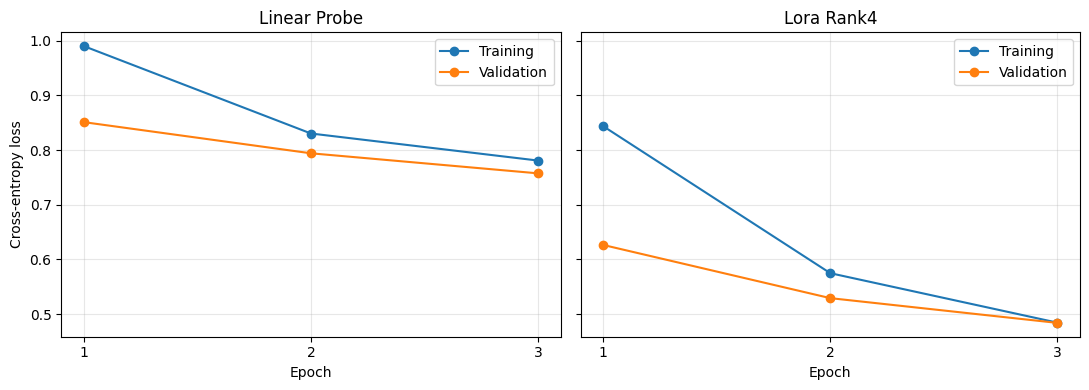

,experiment,best_epoch,train_loss_at_best_epoch,best_validation_loss,test_loss,test_balanced_accuracy,test_macro_f1
0,linear_probe,3,0.780842,0.757463,0.776818,0.271567,0.299268
1,lora_rank4,3,0.484513,0.484088,0.482727,0.601487,0.621189


Loss curves saved to: D:\LORA\results\loss_curves.png


In [13]:
import matplotlib.pyplot as plt
from IPython.display import display

history_path = RESULTS_DIR / "training_history.csv"
metrics_path = RESULTS_DIR / "comparison_metrics.csv"

if "history_df" not in globals() and history_path.exists() and metrics_path.exists():
    history_df = pd.read_csv(history_path)
    metrics_df = pd.read_csv(metrics_path)

if "history_df" in globals() and "metrics_df" in globals():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for axis, experiment_name in zip(axes, ("linear_probe", "lora_rank4")):
        method_history = history_df[history_df["experiment"] == experiment_name]
        axis.plot(method_history["epoch"], method_history["train_loss"], marker="o", label="Training")
        axis.plot(method_history["epoch"], method_history["validation_loss"], marker="o", label="Validation")
        axis.set_title(experiment_name.replace("_", " ").title())
        axis.set_xlabel("Epoch")
        axis.set_xticks(range(1, EPOCHS + 1))
        axis.grid(True, alpha=0.3)
        axis.legend()
    axes[0].set_ylabel("Cross-entropy loss")
    fig.tight_layout()
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(RESULTS_DIR / "loss_curves.png", dpi=160, bbox_inches="tight")
    plt.show()
    display(metrics_df)
    print(f"Loss curves saved to: {(RESULTS_DIR / 'loss_curves.png').resolve()}")
else:
    print("No measured results found. Run the opt-in training cell to generate the comparison table and loss curves.")